In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df=pd.read_excel("4877028-Retail_Sales_Data.xlsx")
df

,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag
0,13-04-2023,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,29973.06,39,1168949.34,5,1.110502e+06,Returning,Debit Card,Yes,422,4.4,South,0
1,25-10-2024,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,46933.78,2,93867.56,15,7.978743e+04,Returning,UPI,No,302,4.1,North,0
2,28-02-2023,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,39280.28,44,1728332.32,15,1.469082e+06,Returning,Cash,No,184,3.8,East,0
3,16-06-2023,STR_102,Bangalore,PRD_014,Home Appliances,Kitchen,Whirlpool,40439.03,9,363951.27,5,3.457537e+05,New,UPI,Yes,493,3.7,South,0
4,23-05-2024,STR_108,Ahmedabad,PRD_932,Fashion,Women Clothing,Puma,9193.58,4,36774.32,5,3.493560e+04,Returning,Credit Card,No,359,3.5,West,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72995,2024-12-03 00:00:00,STR_105,Pune,PRD_449,Electronics,Accessories,Samsung,48317.57,1,48317.57,15,4.106993e+04,Returning,Credit Card,No,367,4.9,West,0
72996,2023-11-11 00:00:00,STR_108,Ahmedabad,PRD_410,Sports,Gym Equipment,Yonex,6368.97,29,184700.13,0,1.847001e+05,Returning,Debit Card,No,139,4.9,West,0
72997,24-05-2023,STR_108,Ahmedabad,PRD_346,Groceries,Snacks,Britannia,28912.38,26,751721.88,10,6.765497e+05,New,UPI,No,309,3.9,West,0
72998,2024-09-12 00:00:00,STR_103,Delhi,PRD_285,Groceries,Snacks,Nestle,34522.32,24,828535.68,0,8.285357e+05,Returning,Debit Card,No,67,3.9,North,0


In [3]:
df.shape

(73000, 19)

In [4]:
df.columns

Index(['Date', 'Store_ID', 'Store_Location', 'Product_ID', 'Product_Category',
       'Product_Subcategory', 'Brand', 'Unit_Price', 'Units_Sold',
       'Total_Sales', 'Discount_Percentage', 'Revenue', 'Customer_Type',
       'Payment_Mode', 'Promotion_Applied', 'Stock_On_Hand', 'Store_Rating',
       'Region', 'Holiday_Flag'],
      dtype='object')

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

,0
Date,0
Store_ID,0
Store_Location,0
Product_ID,0
Product_Category,0
Product_Subcategory,0
Brand,0
Unit_Price,0
Units_Sold,0
Total_Sales,0


In [7]:
df.describe()

,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Stock_On_Hand,Store_Rating,Holiday_Flag
count,73000.000000,73000.000000,7.300000e+04,73000.000000,7.300000e+04,73000.000000,73000.000000,73000.000000
mean,25110.208554,24.894589,6.261382e+05,10.010411,5.634765e+05,274.624712,4.249421,0.012288
std,14393.607981,14.134824,5.448548e+05,7.064131,4.938905e+05,129.663977,0.434722,0.110167
min,100.110000,1.000000,1.447000e+02,0.000000,1.229950e+02,50.000000,3.500000,0.000000
25%,12728.855000,13.000000,1.759852e+05,5.000000,1.575377e+05,162.000000,3.900000,0.000000
50%,25071.800000,25.000000,4.713577e+05,10.000000,4.223565e+05,274.000000,4.200000,0.000000
75%,37557.337500,37.000000,9.539864e+05,15.000000,8.571156e+05,387.000000,4.600000,0.000000
max,49999.850000,49.000000,2.447350e+06,20.000000,2.447350e+06,499.000000,5.000000,1.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73000 entries, 0 to 72999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 73000 non-null  object 
 1   Store_ID             73000 non-null  object 
 2   Store_Location       73000 non-null  object 
 3   Product_ID           73000 non-null  object 
 4   Product_Category     73000 non-null  object 
 5   Product_Subcategory  73000 non-null  object 
 6   Brand                73000 non-null  object 
 7   Unit_Price           73000 non-null  float64
 8   Units_Sold           73000 non-null  int64  
 9   Total_Sales          73000 non-null  float64
 10  Discount_Percentage  73000 non-null  int64  
 11  Revenue              73000 non-null  float64
 12  Customer_Type        73000 non-null  object 
 13  Payment_Mode         73000 non-null  object 
 14  Promotion_Applied    73000 non-null  object 
 15  Stock_On_Hand        73000 non-null 

In [9]:
df['Date']

,Date
0,13-04-2023
1,25-10-2024
2,28-02-2023
3,16-06-2023
4,23-05-2024
...,...
72995,2024-12-03 00:00:00
72996,2023-11-11 00:00:00
72997,24-05-2023
72998,2024-09-12 00:00:00


In [10]:
#DATE IN FORM OF TEXT DTYPE
df['Date_text'] = df['Date'].apply(lambda x: isinstance(x, str))

In [11]:
text_part = pd.to_datetime(df.loc[df['Date_text'], 'Date'], format='%d-%m-%Y')

dt_part = pd.to_datetime(df.loc[~df['Date_text'], 'Date'])
dt_part = pd.to_datetime(dict(year=dt_part.dt.year, month=dt_part.dt.day, day=dt_part.dt.month))

df['Date_fixed'] = pd.concat([text_part, dt_part]).sort_index()


In [12]:
print(df['Date_fixed'].min(), df['Date_fixed'].max())
print(df['Date_fixed'].nunique())
df['Date']=df['Date_fixed']

2023-01-01 00:00:00 2024-12-31 00:00:00
731


In [13]:
from datetime import datetime
df['Date']=pd.to_datetime(df['Date'],format='%d-%m-%Y')
df['Date']

,Date
0,2023-04-13
1,2024-10-25
2,2023-02-28
3,2023-06-16
4,2024-05-23
...,...
72995,2024-03-12
72996,2023-11-11
72997,2023-05-24
72998,2024-12-09


In [14]:
daily_sales=df.groupby("Date")["Revenue"].sum().reset_index()

daily_sales.sort_values(by='Date')

,Date,Revenue
0,2023-01-01,5.198072e+07
1,2023-01-02,5.011216e+07
2,2023-01-03,5.438981e+07
3,2023-01-04,5.308914e+07
4,2023-01-05,5.954055e+07
...,...,...
726,2024-12-27,4.455307e+07
727,2024-12-28,6.385939e+07
728,2024-12-29,6.325796e+07
729,2024-12-30,5.649771e+07


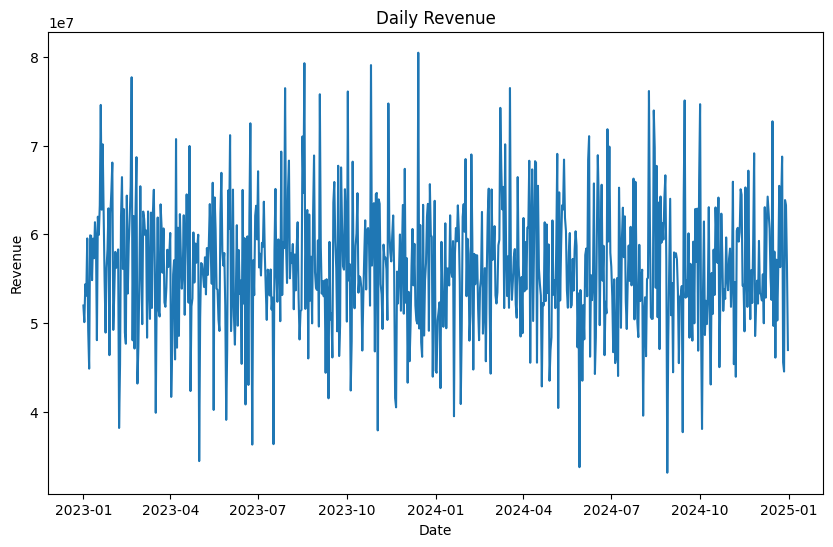

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,6))
plt.plot(daily_sales['Date'],daily_sales['Revenue'])
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.title('Daily Revenue')
plt.show()


Daily revenue bonuces between about 35M and 80 M with no clear upward or downward trend

In [16]:
daily_sales.shape

(731, 2)

In [17]:
df['month'] = df['Date'].dt.to_period('M')
monthly_sales = df.groupby('month')['Revenue'].sum().reset_index()
monthly_sales = monthly_sales.sort_values(by='month')
monthly_sales['month'] = monthly_sales['month'].dt.strftime('%m-%Y')
monthly_sales.head()

,month,Revenue
0,01-2023,1.801385e+09
1,02-2023,1.575642e+09
2,03-2023,1.758672e+09
3,04-2023,1.678882e+09
4,05-2023,1.710369e+09


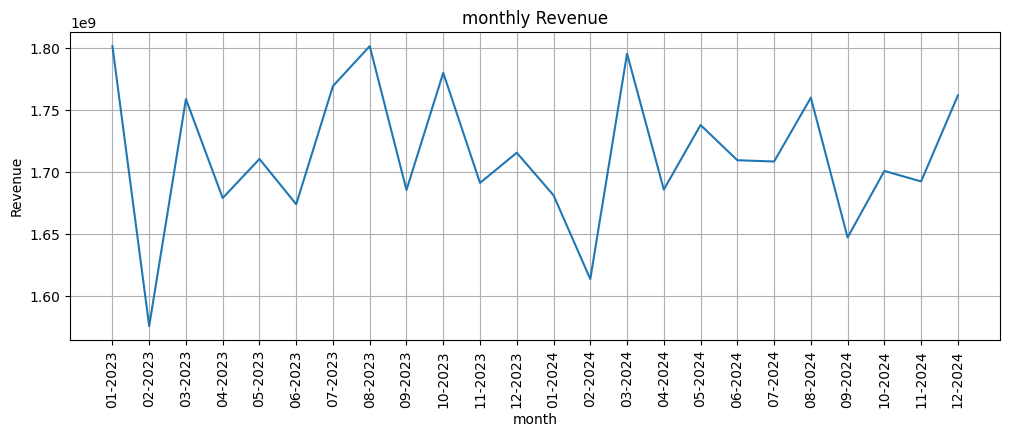

In [18]:
plt.figure(figsize=(12,4))
plt.plot(monthly_sales['month'],monthly_sales['Revenue'])
plt.xlabel('month')
plt.ylabel('Revenue')
plt.xticks(rotation=90)
plt.title('monthly Revenue')
plt.grid(True)
plt.show()

monthly rvenue stays between 1.5B and 1.8, so busniess is stable

February is the lowest month in the both years, probably because of fewer days

In [19]:
monthly_sales['Revenue'].describe()

,Revenue
count,2.400000e+01
mean,1.713908e+09
std,5.773986e+07
min,1.575642e+09
25%,1.684302e+09
50%,1.708853e+09
75%,1.760239e+09
max,1.801385e+09


In [20]:
print(df['Product_Category'].nunique())
print(df['Product_Subcategory'].nunique())
print(df['Store_Location'].nunique())

5
15
8


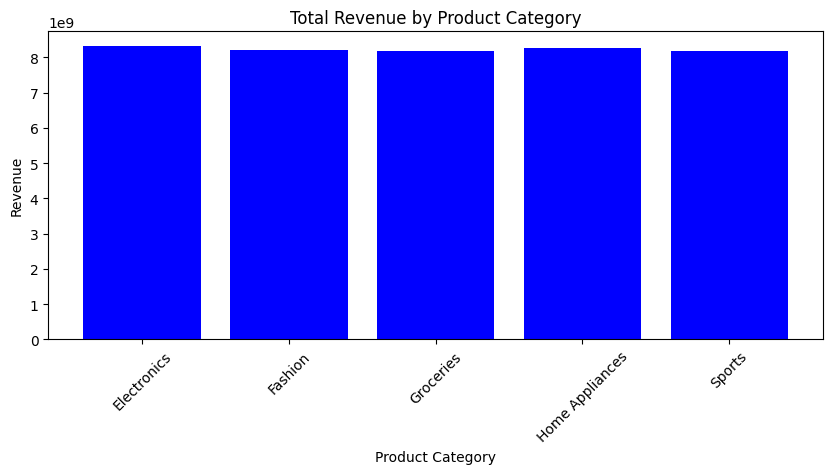

In [21]:
category_revenue = df.groupby('Product_Category')['Revenue'].sum().reset_index()

plt.figure(figsize=(10,4))
plt.bar(x=category_revenue['Product_Category'], height=category_revenue['Revenue'], color='blue')
plt.xlabel('Product Category')
plt.ylabel('Revenue')
plt.title('Total Revenue by Product Category')
plt.xticks(rotation=45)
plt.show()

All 5 categories earns almost the same, Electronics is bit slightly ahead

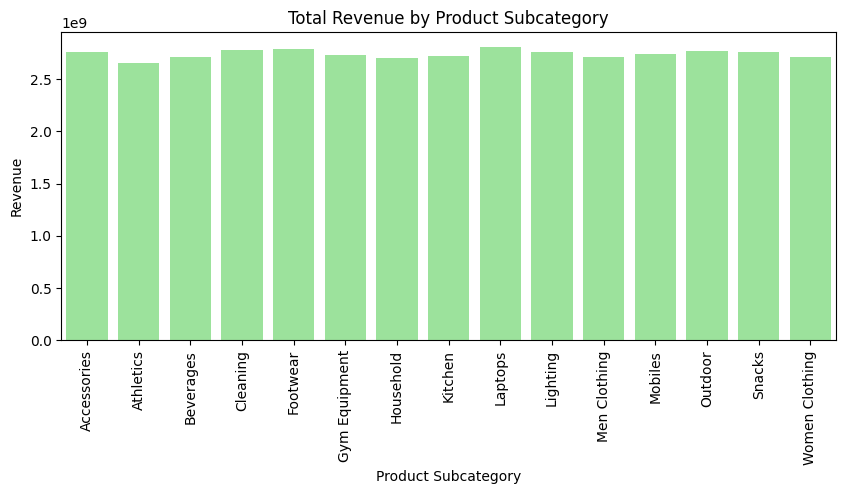

In [22]:
subcategory_revenue = df.groupby('Product_Subcategory')['Revenue'].sum().reset_index()

plt.figure(figsize=(10,4))
sns.barplot(x=subcategory_revenue['Product_Subcategory'], y=subcategory_revenue['Revenue'], color='lightgreen')
plt.xlabel('Product Subcategory')
plt.ylabel('Revenue')
plt.title('Total Revenue by Product Subcategory')
plt.xticks(rotation=90)
plt.show()

Among all the 15 subcategories Laptop is heighest and Athletics is lowest

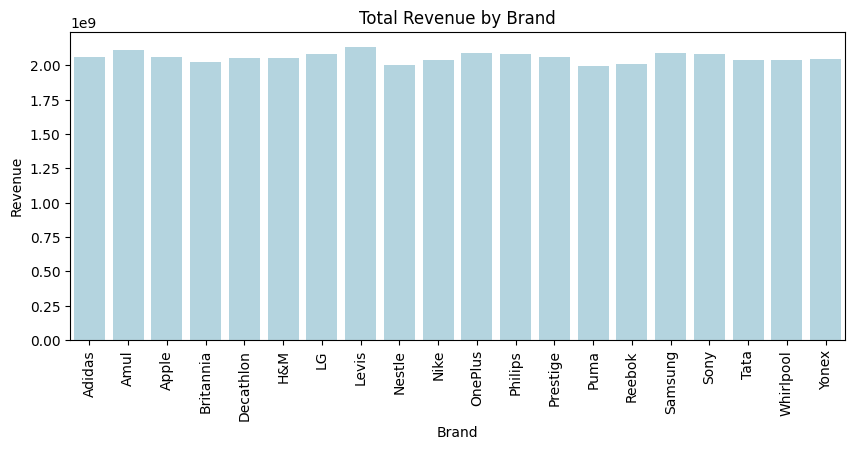

In [23]:
Brand_revenue = df.groupby('Brand')['Revenue'].sum().reset_index()

plt.figure(figsize=(10,4))
sns.barplot(x=Brand_revenue['Brand'], y=Brand_revenue['Revenue'], color='lightblue')
plt.xlabel('Brand')
plt.ylabel('Revenue')
plt.title('Total Revenue by Brand')
plt.xticks(rotation=90)
plt.show()


All Brands are slightly close to each other around 2B

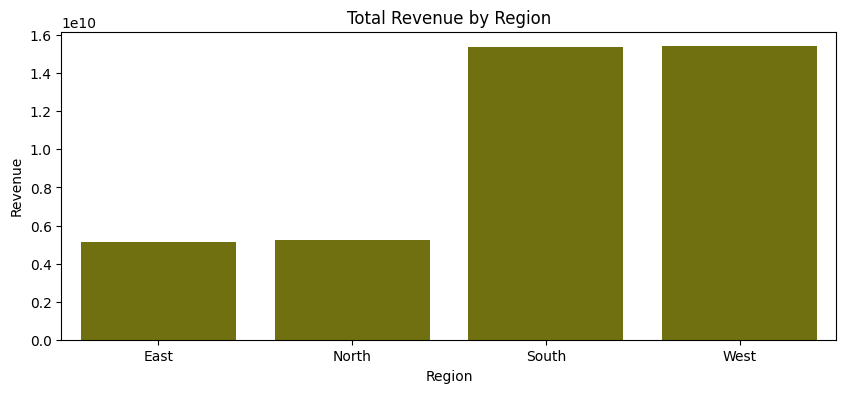

In [24]:
region_revenue = df.groupby('Region')['Revenue'].sum().reset_index()

plt.figure(figsize=(10,4))
sns.barplot(x=region_revenue['Region'], y=region_revenue['Revenue'], color='olive')
plt.xlabel('Region')
plt.ylabel('Revenue')
plt.title('Total Revenue by Region')
plt.show()


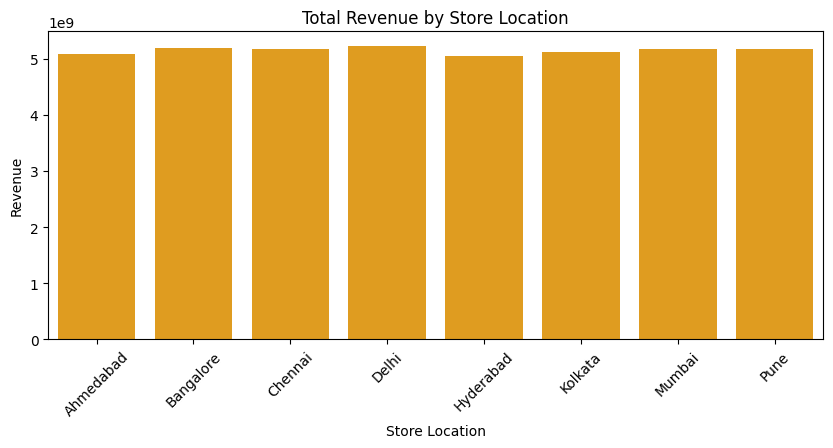

In [25]:
location_revenue = df.groupby('Store_Location')['Revenue'].sum().reset_index()

plt.figure(figsize=(10,4))
sns.barplot(x=location_revenue['Store_Location'], y=location_revenue['Revenue'], color='orange')
plt.xlabel('Store Location')
plt.ylabel('Revenue')
plt.title('Total Revenue by Store Location')
plt.xticks(rotation=45)
plt.show()

South and West each bring more revenue might because of number of store located in the south and west regions

In [26]:
df.columns

Index(['Date', 'Store_ID', 'Store_Location', 'Product_ID', 'Product_Category',
       'Product_Subcategory', 'Brand', 'Unit_Price', 'Units_Sold',
       'Total_Sales', 'Discount_Percentage', 'Revenue', 'Customer_Type',
       'Payment_Mode', 'Promotion_Applied', 'Stock_On_Hand', 'Store_Rating',
       'Region', 'Holiday_Flag', 'Date_text', 'Date_fixed', 'month'],
      dtype='object')

In [27]:
promotion_revenue=df.groupby('Promotion_Applied')['Revenue'].count()
promotion_revenue

,Revenue
Promotion_Applied,
No,51151
Yes,21849


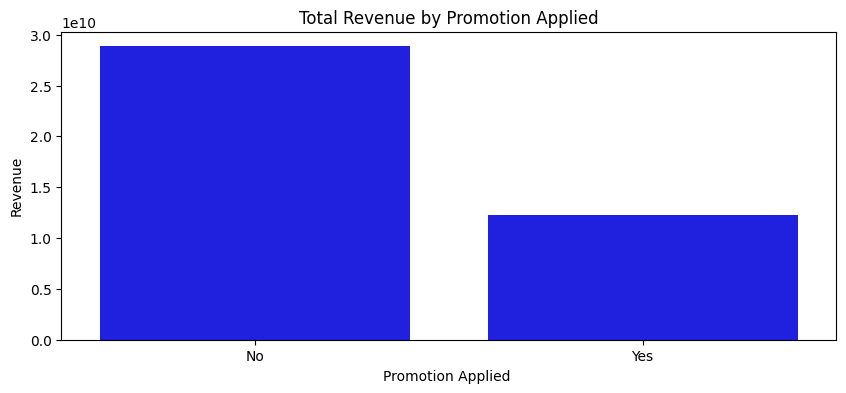

In [28]:
promotion_revenue=df.groupby('Promotion_Applied')['Revenue'].sum().reset_index()
promotion_revenue
plt.figure(figsize=(10,4))
sns.barplot(x=promotion_revenue['Promotion_Applied'], y=promotion_revenue['Revenue'], color='blue')
plt.xlabel('Promotion Applied ')
plt.ylabel('Revenue')
plt.title('Total Revenue by Promotion Applied')
plt.show()

only around 30% of order had promotions

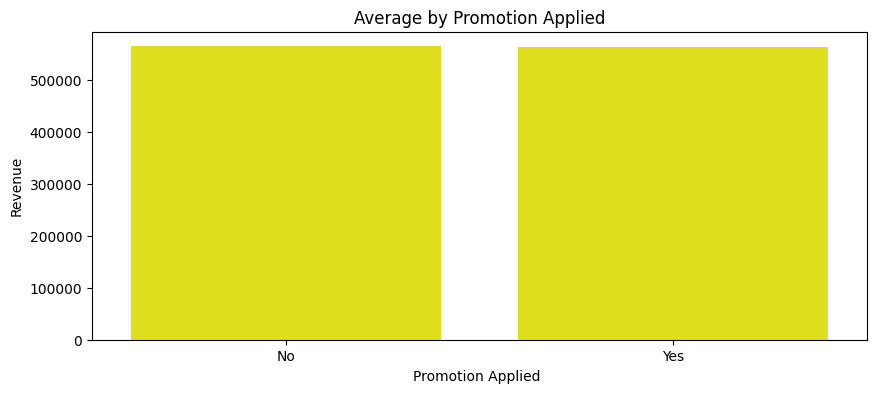

In [29]:
promotion_revenue=df.groupby('Promotion_Applied')['Revenue'].mean().reset_index()
promotion_revenue
plt.figure(figsize=(10,4))
sns.barplot(x=promotion_revenue['Promotion_Applied'], y=promotion_revenue['Revenue'], color='yellow')
plt.xlabel('Promotion Applied ')
plt.ylabel('Revenue')
plt.title('Average by Promotion Applied')
plt.show()

Average value is amost same with or without promotion, so promotion did not make orders bigger

In [30]:
discount_revenue=df.groupby('Discount_Percentage')['Revenue'].count()
discount_revenue

,Revenue
Discount_Percentage,
0,14560
5,14556
10,14600
15,14740
20,14544


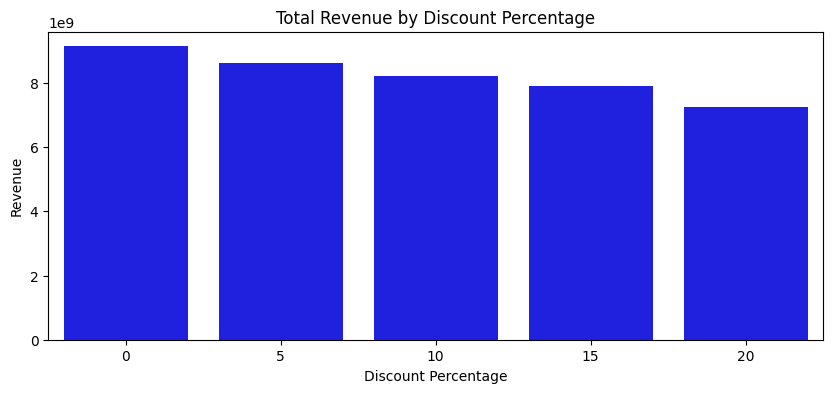

In [31]:
discount_revenue=df.groupby('Discount_Percentage')['Revenue'].sum().reset_index()
discount_revenue
plt.figure(figsize=(10,4))
sns.barplot(x=discount_revenue['Discount_Percentage'], y=discount_revenue['Revenue'], color='blue')
plt.xlabel('Discount Percentage')
plt.ylabel('Revenue')
plt.title('Total Revenue by Discount Percentage')
plt.show()

has high revenue at the 0% discount and low revenue when 20% discount

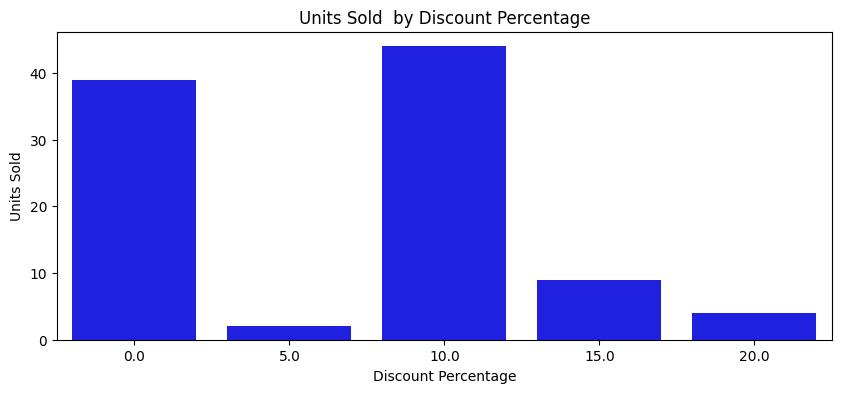

In [32]:
discount_revenue=df.groupby('Discount_Percentage')['Revenue'].mean().reset_index()
discount_revenue
plt.figure(figsize=(10,4))
sns.barplot(x=discount_revenue['Discount_Percentage'], y=df['Units_Sold'], color='blue')
plt.xlabel('Discount Percentage')
plt.ylabel('Units Sold')
plt.title('Units Sold  by Discount Percentage')
plt.show()

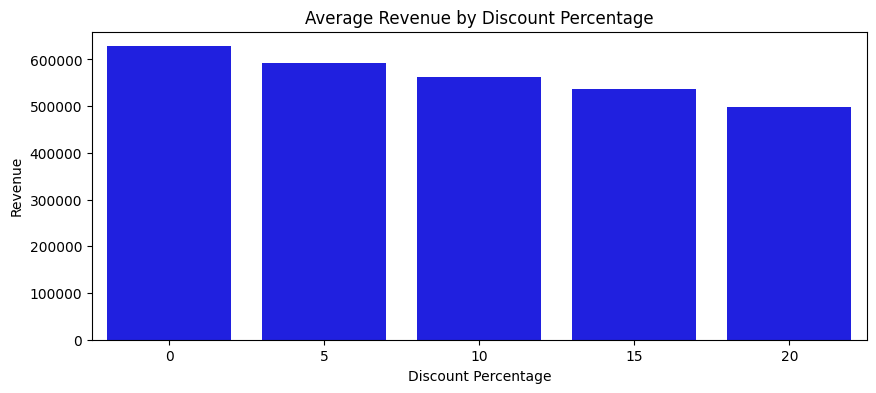

In [33]:
discount_revenue=df.groupby('Discount_Percentage')['Revenue'].mean().reset_index()
discount_revenue
plt.figure(figsize=(10,4))
sns.barplot(x=discount_revenue['Discount_Percentage'], y=discount_revenue['Revenue'], color='blue')
plt.xlabel('Discount Percentage')
plt.ylabel('Revenue')
plt.title('Average Revenue by Discount Percentage')
plt.show()

In [34]:
holiday_revenue=df.groupby('Holiday_Flag')['Revenue'].count()
holiday_revenue

,Revenue
Holiday_Flag,
0,72103
1,897


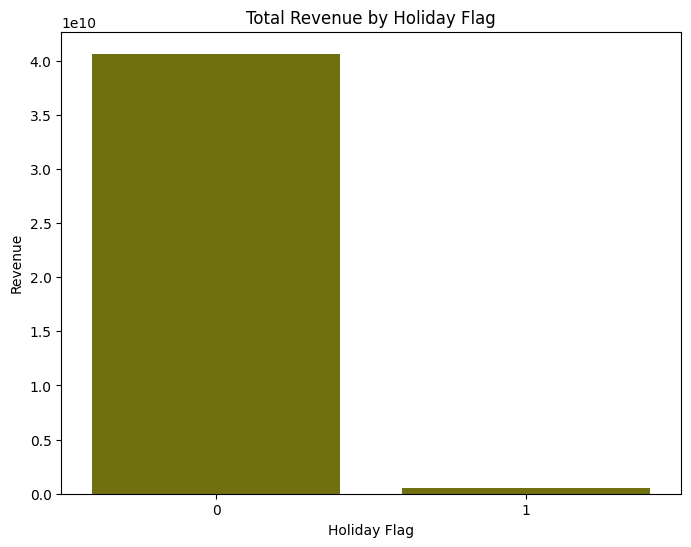

In [35]:
holiday_revenue=df.groupby('Holiday_Flag')['Revenue'].sum().reset_index()
plt.figure(figsize=(8,6))
sns.barplot(x=holiday_revenue['Holiday_Flag'],y=holiday_revenue['Revenue'],color='olive')
plt.title('Total Revenue by Holiday Flag')
plt.xlabel("Holiday Flag")
plt.ylabel("Revenue")
plt.show()

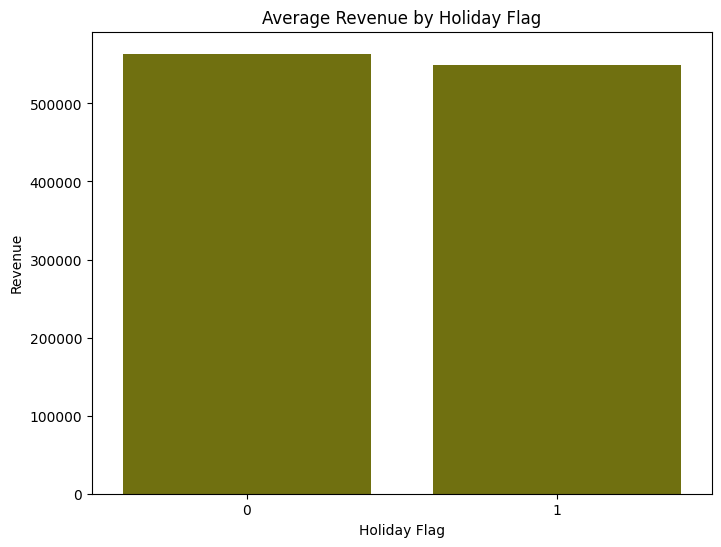

In [36]:
holiday_revenue=df.groupby('Holiday_Flag')['Revenue'].mean().reset_index()
plt.figure(figsize=(8,6))
sns.barplot(x=holiday_revenue['Holiday_Flag'],y=holiday_revenue['Revenue'],color='olive')
plt.title('Average Revenue by Holiday Flag')
plt.xlabel("Holiday Flag")
plt.ylabel("Revenue")
plt.show()

Average revenue on flagged rows is slightly lower than on normal rows. There is no holiday boost.

In [37]:
df['Month']=df['Date'].dt.month
df['Year']=df['Date'].dt.year

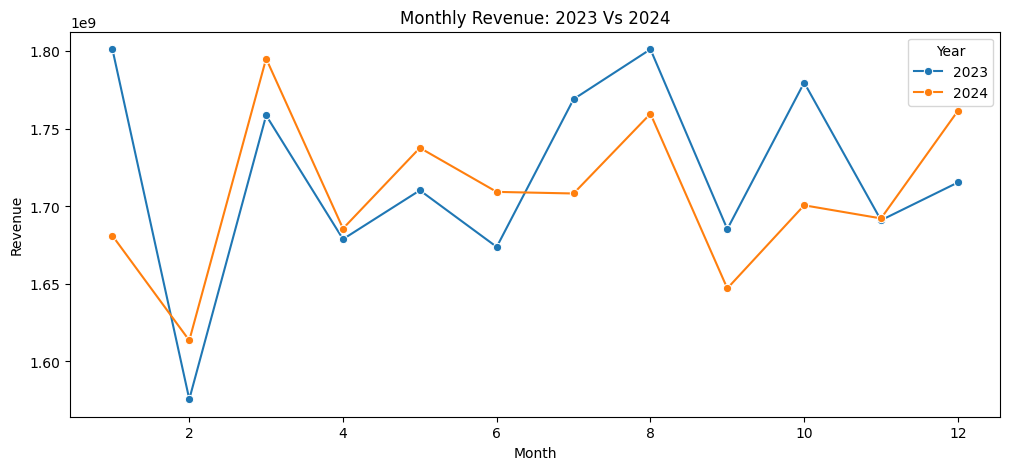

In [38]:
monthly_trend = df.groupby(['Year', 'Month'])['Revenue'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_trend, x='Month', y='Revenue', hue='Year', marker='o', palette='tab10')
plt.title("Monthly Revenue: 2023 Vs 2024")
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.show()

The two years follow a similar shape, but no month shows a big or steady change.


In [39]:
monthly_comparision=monthly_trend.pivot(index='Month',columns='Year',values='Revenue')
monthly_comparision['growth_percentage']=((monthly_comparision[2024]-monthly_comparision[2023])/monthly_comparision[2023])*100
monthly_comparision

Year,2023,2024,growth_percentage
Month,,,
1,1.801385e+09,1.681103e+09,-6.677171
2,1.575642e+09,1.613559e+09,2.406444
3,1.758672e+09,1.795332e+09,2.084523
4,1.678882e+09,1.685703e+09,0.406327
5,1.710369e+09,1.737768e+09,1.601925
6,1.673871e+09,1.709369e+09,2.120708
7,1.769177e+09,1.708338e+09,-3.438805
8,1.801351e+09,1.759781e+09,-2.307713
9,1.685368e+09,1.647125e+09,-2.269114


In [40]:
rating_revenue = df.groupby('Store_Rating')['Revenue'].count()
rating_revenue

,Revenue
Store_Rating,
3.5,2412
3.6,4797
3.7,4958
3.8,4954
3.9,4784
4.0,4847
4.1,4968
4.2,4843
4.3,4876


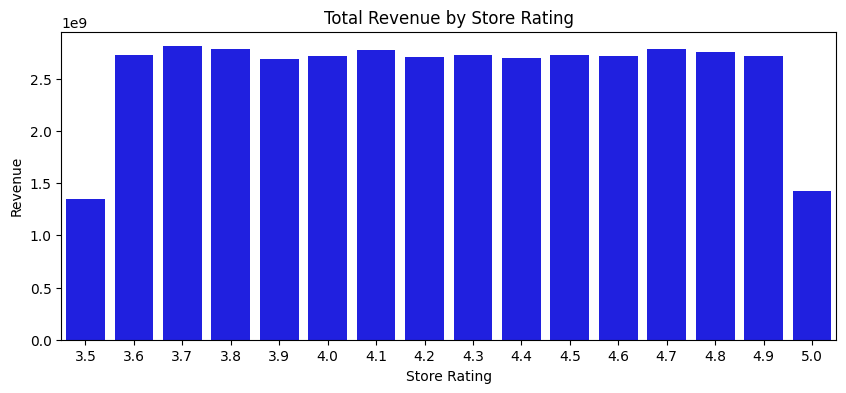

In [41]:
rating_revenue = df.groupby('Store_Rating')['Revenue'].sum().reset_index()

plt.figure(figsize=(10,4))
sns.barplot(x=rating_revenue['Store_Rating'], y=rating_revenue['Revenue'], color='blue')
plt.xlabel('Store Rating')
plt.ylabel('Revenue')
plt.title('Total Revenue by Store Rating')
plt.show()

The bars for ratings 3.5 and 5.0 are about half as tall as the others, only because they have about half as many rows.
Rating has no visible link to revenue.

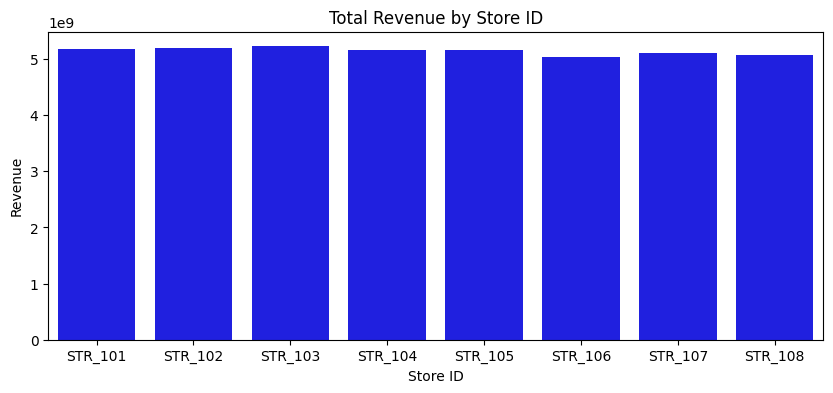

In [42]:
id_revenue = df.groupby('Store_ID')['Revenue'].sum().reset_index()

plt.figure(figsize=(10,4))
sns.barplot(x=id_revenue['Store_ID'], y=id_revenue['Revenue'], color='blue')
plt.xlabel('Store ID')
plt.ylabel('Revenue')
plt.title('Total Revenue by Store ID')
plt.show()

STR_103 earns the most and STR_106 the least. The gap is under 4%-5%.


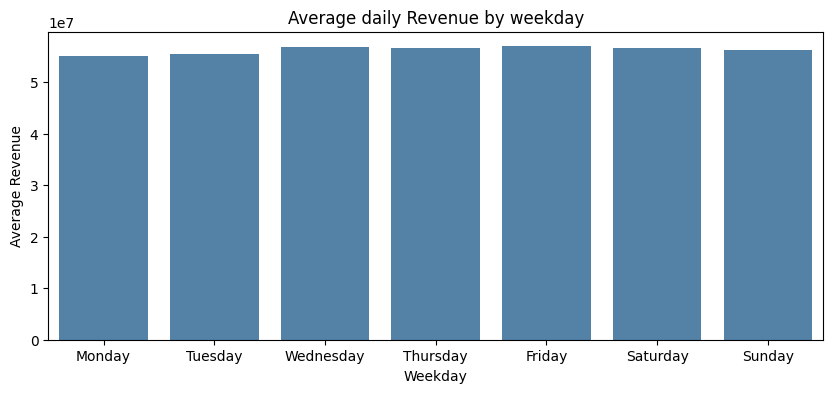

In [43]:
daily_sales['weekday']=daily_sales['Date'].dt.day_name()
daily_sales['is_weekend']=daily_sales['Date'].dt.dayofweek>= 5
order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
avy_by_day=daily_sales.groupby('weekday')['Revenue'].mean().reindex(order)
plt.figure(figsize=(10,4))
sns.barplot(x=avy_by_day.index,y=avy_by_day.values,color='steelblue')
plt.title("Average daily Revenue by weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Revenue")
plt.show()

Average daily revenue is about ₹55M to ₹57M on every day of the week.

Weekends are no better than weekdays, so there is no weekly pattern.

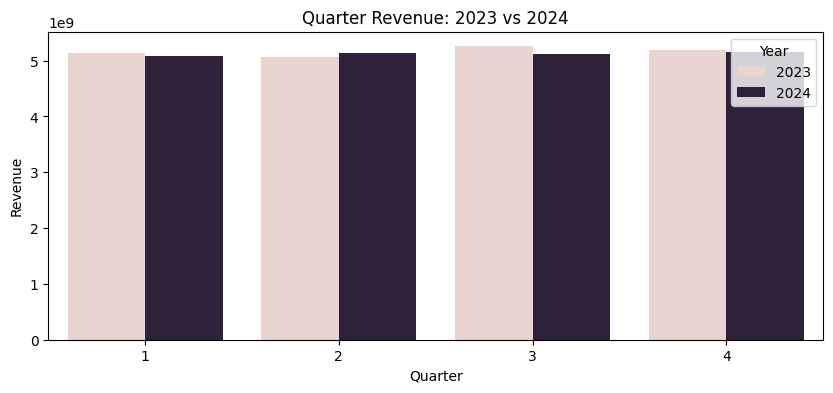

In [44]:
df['Quarter']=df['Date'].dt.quarter
quarterly=df.groupby(['Year','Quarter'])['Revenue'].sum().reset_index()
plt.figure(figsize=(10,4))
sns.barplot(data=quarterly, x='Quarter', y='Revenue', hue='Year')
plt.title("Quarter Revenue: 2023 vs 2024")
plt.show()

In [45]:
# by category
df.groupby('Product_Category').agg(
    Total_Revenue=('Revenue','sum'),
    Avg_Order_Value=('Revenue','mean'),
    Avg_Units=('Units_Sold','mean')
).sort_values('Total_Revenue', ascending=False)

# by store
df.groupby('Store_ID').agg(
    Total_Revenue=('Revenue','sum'),
    Avg_Order_Value=('Revenue','mean'),
    Avg_Units=('Units_Sold','mean')
).sort_values('Total_Revenue', ascending=False)

# by promotion
df.groupby('Promotion_Applied').agg(
    Total_Revenue=('Revenue','sum'),
    Avg_Order_Value=('Revenue','mean'),
    Avg_Units=('Units_Sold','mean')
)

,Total_Revenue,Avg_Order_Value,Avg_Units
Promotion_Applied,,,
No,2.884746e+10,563966.657888,24.900373
Yes,1.228632e+10,562328.909671,24.881047


In [46]:
store_summary = df.groupby('Store_ID').agg(
    Total_Revenue=('Revenue','sum'),
    Avg_Order_Value=('Revenue','mean'),
    Total_Units=('Units_Sold','sum'),
    Orders=('Revenue','count'),
    Avg_Rating=('Store_Rating','mean'),
    Avg_Discount=('Discount_Percentage','mean')
)

# share of revenue by category for each store
cat_mix = pd.crosstab(df['Store_ID'], df['Product_Category'],
                      values=df['Revenue'], aggfunc='sum', normalize='index')

store_summary = store_summary.join(cat_mix)
store_summary = store_summary.join(df.groupby('Store_ID')['Store_Location'].first())
store_summary

,Total_Revenue,Avg_Order_Value,Total_Units,Orders,Avg_Rating,Avg_Discount,Electronics,Fashion,Groceries,Home Appliances,Sports,Store_Location
Store_ID,,,,,,,,,,,,
STR_101,5.169675e+09,571929.999659,226670,9039,4.250183,10.091824,0.196123,0.196393,0.194912,0.208446,0.204127,Mumbai
STR_102,5.186277e+09,565323.371035,228384,9174,4.250981,9.998365,0.208289,0.203024,0.196324,0.197561,0.194802,Bangalore
STR_103,5.223064e+09,569395.428304,229475,9173,4.250714,9.968931,0.203466,0.201646,0.198260,0.201985,0.194643,Delhi
STR_104,5.165937e+09,562370.724772,228580,9186,4.250501,10.113760,0.203003,0.199502,0.198585,0.206945,0.191965,Chennai
STR_105,5.161899e+09,557801.889120,227715,9254,4.245418,10.076724,0.206004,0.196437,0.204386,0.194097,0.199075,Pune
STR_106,5.040776e+09,559216.363155,223084,9014,4.249467,9.944531,0.197007,0.207399,0.206891,0.189243,0.199461,Hyderabad
STR_107,5.107832e+09,559088.474357,229403,9136,4.248172,9.951839,0.201662,0.201854,0.197008,0.202080,0.197396,Kolkata
STR_108,5.078322e+09,562757.310455,223994,9024,4.249978,9.935173,0.202132,0.191621,0.192802,0.206461,0.206984,Ahmedabad


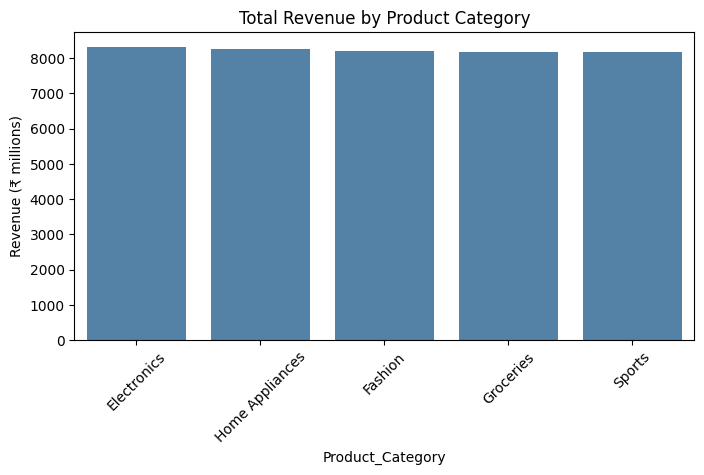

In [47]:
cat = df.groupby('Product_Category')['Revenue'].sum().sort_values(ascending=False) / 1e6

plt.figure(figsize=(8,4))
sns.barplot(x=cat.index, y=cat.values, color='steelblue')
plt.ylabel('Revenue (₹ millions)')
plt.title('Total Revenue by Product Category')
plt.xticks(rotation=45)
plt.show()

Revenue is flat across time, stores, categories and brands.
Small differences exist but none is strong, so a forecast will mostly follow the average level.

**MODELS**

In [48]:
ts=df.groupby('Date')['Revenue'].sum().sort_index()
ts.index=pd.to_datetime(ts.index)
ts=ts.asfreq('D')
print(ts.isnull().sum())
print(len(ts))

0
731


In [49]:
ts.describe()

,Revenue
count,7.310000e+02
mean,5.627056e+07
std,7.364337e+06
min,3.315828e+07
25%,5.183393e+07
50%,5.610039e+07
75%,6.075116e+07
max,8.045082e+07


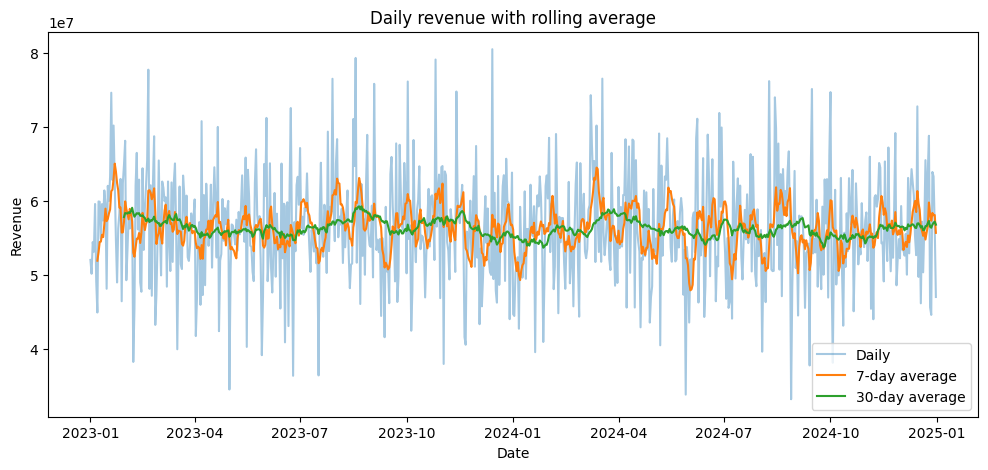

In [50]:
plt.figure(figsize=(12,5))
plt.plot(ts, alpha=0.4,label='Daily')
plt.plot(ts.rolling(7).mean(),label='7-day average')
plt.plot(ts.rolling(30).mean(),label='30-day average')
plt.title('Daily revenue with rolling average')
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.show()

The daily line is noisy, and the 30-day average stays almost flat.
That means no clear trend.whereas 7-day average moves up and down but there is no repeating pattern

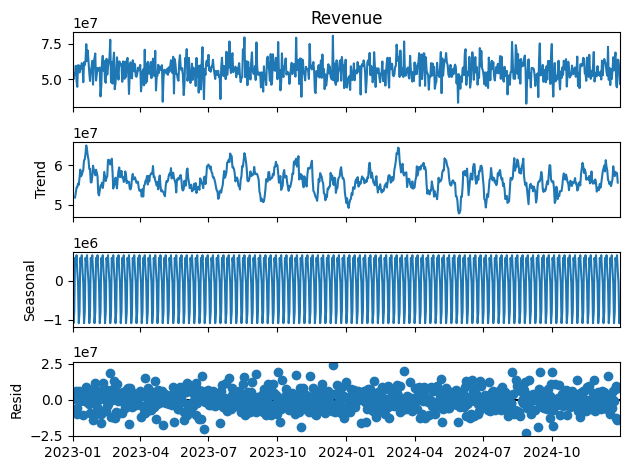

In [51]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
result=seasonal_decompose(ts, model='additive',period=7)
result.plot()
plt.show()

In [52]:
tr=ts[:'2024-09-30']
te=ts['2024-10-01':]
print(len(tr),len(te))

639 92


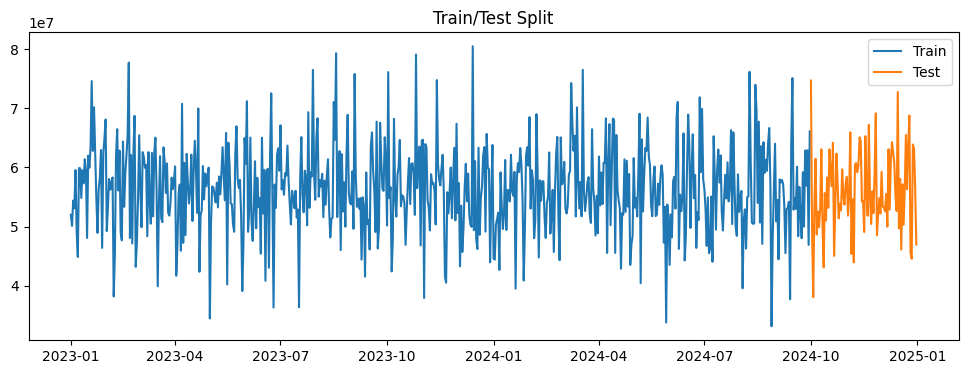

In [53]:
plt.figure(figsize=(12,4))
plt.plot(tr,label='Train')
plt.plot(te,label='Test')
plt.title("Train/Test Split")
plt.legend()
plt.show()

In [54]:
def evaluate(actual,pred):
  mae=mean_absolute_error(actual,pred)
  rmse=np.sqrt(mean_squared_error(actual,pred))
  mape=np.mean(np.abs((actual-pred)/actual))*100
  return mae,rmse,mape

In [55]:
pred_mean=pd.Series(tr.mean(),index=te.index)
pred_last30=pd.Series(tr[-30:].mean(),index=te.index)
last_week=tr[-7:].values
pred_snaive=pd.Series(np.tile(last_week,14)[:len(te)],index=te.index)

for name,p in [('Mean',pred_mean),('last 30 avg',pred_last30),('Seasonal naive',pred_snaive)]:
  print(name,evaluate(te,p))

Mean (5437034.180388167, np.float64(6775747.237422127), np.float64(9.939911806729087))
last 30 avg (5365627.60001413, np.float64(6862760.772763642), np.float64(9.567578728572066))
Seasonal naive (8326170.665874998, np.float64(10245509.514650606), np.float64(15.31176414353014))


In [56]:
feat = ts.to_frame('Revenue')
feat['dayofweek'] = feat.index.dayofweek
feat['month'] = feat.index.month
feat['quarter'] = feat.index.quarter
feat['day'] = feat.index.day
feat['is_weekend'] = (feat.index.dayofweek >= 5).astype(int)
feat['t'] = np.arange(len(feat))


In [57]:
x = feat.drop(columns=['Revenue'])
y = feat['Revenue']

In [58]:
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=92, shuffle=False)
print(x_tr.shape, x_te.shape)

(639, 6) (92, 6)


In [59]:
lr=LinearRegression()
lr.fit(x_tr,y_tr)

LinearRegression()

In [60]:
pred_lr=pd.Series(lr.predict(x_te),index=y_te.index)
print("linear Regression:",evaluate(y_te,pred_lr))

linear Regression: (5488284.886250144, np.float64(6921493.514018236), np.float64(9.936439727774646))


In [61]:
rf=RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(x_tr,y_tr)

RandomForestRegressor(n_estimators=200, random_state=42)

In [62]:
pred_rf=pd.Series(rf.predict(x_te),index=x_te.index)
print("Random Forest:",evaluate(y_te,pred_rf))


Random Forest: (5601074.383003694, np.float64(7071237.462651031), np.float64(10.147984457706325))


In [63]:
lr_final = LinearRegression()
lr_final.fit(x, y)

LinearRegression()

In [64]:
future_dates = pd.date_range(start='2025-01-01', periods=90, freq='D')

future = pd.DataFrame(index=future_dates)
future['dayofweek'] = future.index.dayofweek
future['month'] = future.index.month
future['quarter'] = future.index.quarter
future['day'] = future.index.day
future['is_weekend'] = (future.index.dayofweek >= 5).astype(int)
future['t'] = np.arange(len(x), len(x) + 90)

future = future[x.columns]   # same column order as training

In [65]:
future_pred = pd.Series(lr_final.predict(future), index=future_dates)
future_pred.describe()

,0
count,9.000000e+01
mean,5.551870e+07
std,7.371491e+05
min,5.391096e+07
25%,5.501363e+07
50%,5.550198e+07
75%,5.600499e+07
max,5.709300e+07


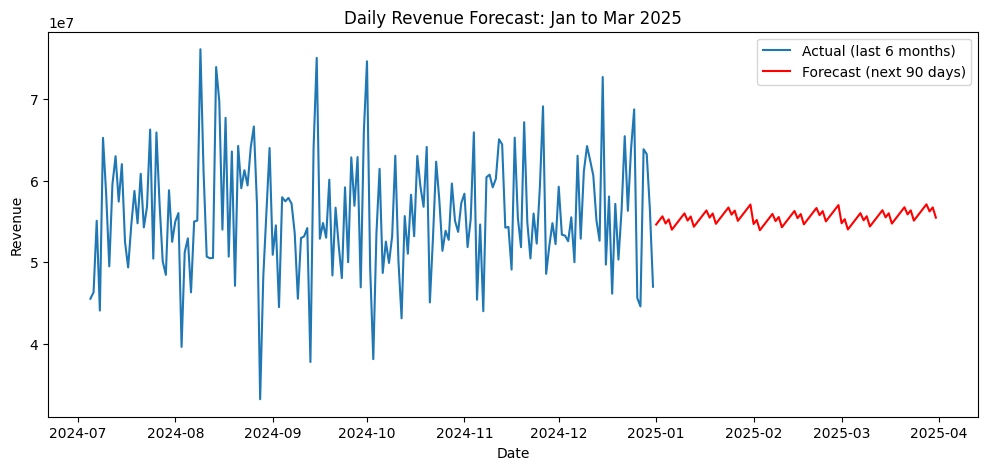

In [66]:
plt.figure(figsize=(12,5))
plt.plot(ts[-180:], label='Actual (last 6 months)')
plt.plot(future_pred, label='Forecast (next 90 days)', color='red')
plt.title('Daily Revenue Forecast: Jan to Mar 2025')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.legend()
plt.show()

In [67]:
models = {
    'Mean': pred_mean,
    'Last 30 days avg': pred_last30,
    'Seasonal naive': pred_snaive,
    'Linear Regression': pred_lr,
    'Random Forest': pred_rf
}

rows = []
for name, p in models.items():
    mae, rmse, mape = evaluate(y_te, p)
    rows.append([name, mae, rmse, mape])

results = pd.DataFrame(rows, columns=['Model', 'MAE', 'RMSE', 'MAPE (%)'])
results = results.round(2).sort_values('MAE').reset_index(drop=True)
results

,Model,MAE,RMSE,MAPE (%)
0,Last 30 days avg,5365627.60,6862760.77,9.57
1,Mean,5437034.18,6775747.24,9.94
2,Linear Regression,5488284.89,6921493.51,9.94
3,Random Forest,5601074.38,7071237.46,10.15
4,Seasonal naive,8326170.67,10245509.51,15.31


In [68]:
results.to_csv('model_results.csv', index=False)

In [69]:
forecast_df = future_pred.reset_index()
forecast_df.columns = ['Date', 'Forecasted_Revenue']
forecast_df.to_csv('forecast.csv', index=False)

In [70]:
features = ['Total_Revenue', 'Avg_Order_Value', 'Orders', 'Avg_Rating', 'Avg_Discount']
X = store_summary[features]
X_scaled = StandardScaler().fit_transform(X)

CLUSTERING-ELBOW METHOD

In [71]:
features = ['Total_Revenue', 'Avg_Order_Value', 'Orders', 'Avg_Rating', 'Avg_Discount']
X = store_summary[features]
X_scaled = StandardScaler().fit_transform(X)

{2: np.float64(0.3121074234927559), 3: np.float64(0.3562118152837457), 4: np.float64(0.28881466836287406), 5: np.float64(0.30150474566261637)}


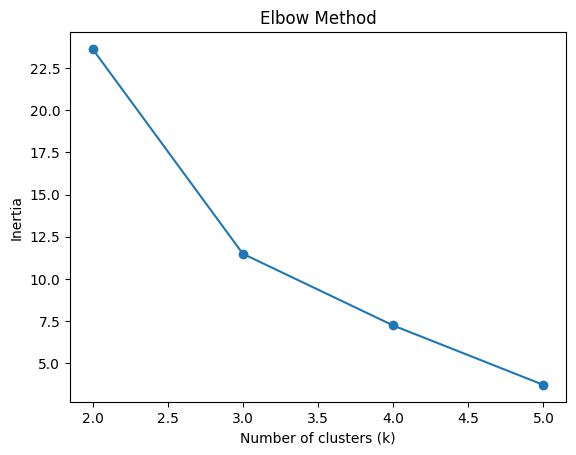

In [72]:
inertia = []
sil = {}
for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil[k] = silhouette_score(X_scaled, km.labels_)

print(sil)

plt.plot(range(2, 6), inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()


K MEANS

In [73]:
km = KMeans(n_clusters=3, random_state=42, n_init=10)
store_summary['Cluster'] = km.fit_predict(X_scaled)

In [74]:
order = store_summary.groupby('Cluster')['Total_Revenue'].mean().sort_values(ascending=False).index
names = {order[0]: 'High', order[1]: 'Medium', order[2]: 'Low'}
store_summary['Segment'] = store_summary['Cluster'].map(names)

store_summary[['Store_Location', 'Total_Revenue', 'Avg_Order_Value', 'Orders', 'Avg_Rating', 'Avg_Discount', 'Segment']].sort_values('Total_Revenue', ascending=False)

,Store_Location,Total_Revenue,Avg_Order_Value,Orders,Avg_Rating,Avg_Discount,Segment
Store_ID,,,,,,,
STR_103,Delhi,5.223064e+09,569395.428304,9173,4.250714,9.968931,High
STR_102,Bangalore,5.186277e+09,565323.371035,9174,4.250981,9.998365,High
STR_101,Mumbai,5.169675e+09,571929.999659,9039,4.250183,10.091824,High
STR_104,Chennai,5.165937e+09,562370.724772,9186,4.250501,10.113760,High
STR_105,Pune,5.161899e+09,557801.889120,9254,4.245418,10.076724,Medium
STR_107,Kolkata,5.107832e+09,559088.474357,9136,4.248172,9.951839,Low
STR_108,Ahmedabad,5.078322e+09,562757.310455,9024,4.249978,9.935173,Low
STR_106,Hyderabad,5.040776e+09,559216.363155,9014,4.249467,9.944531,Low


In [75]:
store_summary.loc['STR_105', 'Segment'] = 'Medium (high volume, low order value)'
store_summary[['Store_Location', 'Total_Revenue', 'Orders', 'Avg_Order_Value', 'Segment']]

,Store_Location,Total_Revenue,Orders,Avg_Order_Value,Segment
Store_ID,,,,,
STR_101,Mumbai,5.169675e+09,9039,571929.999659,High
STR_102,Bangalore,5.186277e+09,9174,565323.371035,High
STR_103,Delhi,5.223064e+09,9173,569395.428304,High
STR_104,Chennai,5.165937e+09,9186,562370.724772,High
STR_105,Pune,5.161899e+09,9254,557801.889120,"Medium (high volume, low order value)"
STR_106,Hyderabad,5.040776e+09,9014,559216.363155,Low
STR_107,Kolkata,5.107832e+09,9136,559088.474357,Low
STR_108,Ahmedabad,5.078322e+09,9024,562757.310455,Low


In [76]:
store_summary.groupby('Segment')[features].mean().round(2)

,Total_Revenue,Avg_Order_Value,Orders,Avg_Rating,Avg_Discount
Segment,,,,,
High,5.186238e+09,567254.88,9143.0,4.25,10.04
Low,5.075644e+09,560354.05,9058.0,4.25,9.94
"Medium (high volume, low order value)",5.161899e+09,557801.89,9254.0,4.25,10.08


In [77]:
store_summary.reset_index().to_csv('store_clusters.csv', index=False)

In [78]:
clean = df.drop(columns=['Date_text', 'Date_fixed', 'month'], errors='ignore')
clean.to_csv('cleaned_sales.csv', index=False)